# Tuần 2: Phát hiện lỗi bề mặt bằng YOLOv8n

**Mục tiêu:** huấn luyện YOLOv8n trên NEU Surface Defect để phát hiện sáu loại lỗi bề mặt thép:
Nứt rạn, Tạp chất lẫn, Vết vá, Rỗ bề mặt, Vảy cán và Trầy xước.

Đây là **baseline Detection riêng trên NEU-DET**. Không dùng YOLOv8 NEU-DET để dự đoán ảnh MVTec bottle ở Tuần 4.

**Đầu ra Tuần 2**
- `splits/train.txt`, `splits/val.txt`, `splits/test.txt`.
- `neu_det_split.yaml`.
- `weights/best.pt`.
- `metrics_yolov8.csv`.
- `du_doan_yolov8_tieng_viet.png`: lưới ảnh đầu ra giống ví dụ, nhưng nhãn bằng tiếng Việt.


In [1]:
from pathlib import Path
from zipfile import ZipFile, BadZipFile
import os
import sys
import random
import subprocess

SEED = 42
random.seed(SEED)

CWD = Path.cwd().resolve()
IS_KAGGLE = Path("/kaggle").exists()
KAGGLE_WORKING = Path("/kaggle/working")
KAGGLE_INPUT = Path("/kaggle/input")


def looks_like_project(path: Path) -> bool:
    return (path / "notebooks").is_dir() and (path / "datasets").is_dir()


def safe_extract_project_zip():
    """
    Nếu project ZIP được gắn qua Kaggle Input, giải nén đúng một lần vào
    /kaggle/working/Industrial_Defect_VQA để notebook có quyền ghi output.
    """
    if not IS_KAGGLE or not KAGGLE_INPUT.is_dir():
        return None

    target = KAGGLE_WORKING / "Industrial_Defect_VQA"
    if looks_like_project(target):
        return target

    for zip_path in KAGGLE_INPUT.glob("**/*.zip"):
        try:
            with ZipFile(zip_path) as archive:
                names = [name.replace("\\", "/") for name in archive.namelist()]
                has_neu = any("NEU-DET/train/images/" in name for name in names)
                has_notebooks = any("/notebooks/" in name or name.startswith("notebooks/") for name in names)
                if not (has_neu and has_notebooks):
                    continue
                target.mkdir(parents=True, exist_ok=True)
                marker = target / f".extracted_{zip_path.stem}"
                if not marker.exists():
                    archive.extractall(target)
                    marker.touch()
                if looks_like_project(target):
                    return target
                # Một số ZIP có thêm thư mục bọc ngoài. Dùng trực tiếp thư mục này,
                # không di chuyển file để tránh ghi đè sai cấu trúc.
                nested = [p for p in target.iterdir() if p.is_dir() and looks_like_project(p)]
                if nested:
                    return nested[0]
        except (BadZipFile, OSError):
            continue
    return None


def find_project_root() -> Path:
    extracted = safe_extract_project_zip()
    candidates = []
    if extracted is not None:
        candidates.append(extracted)
    candidates += [CWD, *CWD.parents]
    kaggle_project = KAGGLE_WORKING / "Industrial_Defect_VQA"
    if kaggle_project.exists():
        candidates.insert(0, kaggle_project)

    checked = set()
    for candidate in candidates:
        try:
            candidate = candidate.resolve()
        except OSError:
            continue
        if str(candidate) in checked:
            continue
        checked.add(str(candidate))
        if looks_like_project(candidate):
            return candidate
    return CWD


def is_neu_root(path: Path) -> bool:
    return (
        path.is_dir()
        and (path / "train" / "images").is_dir()
        and (path / "train" / "labels").is_dir()
        and (path / "test" / "images").is_dir()
        and (path / "test" / "labels").is_dir()
    )


def find_neu_root(project_root: Path):
    checked = []
    candidates = [
        project_root / "datasets" / "detection_yolov8_neu" / "data" / "NEU-DET",
        project_root / "data" / "NEU-DET",
    ]
    for candidate in candidates:
        checked.append(candidate)
        if is_neu_root(candidate):
            return candidate.resolve(), checked

    if KAGGLE_INPUT.is_dir():
        for candidate in KAGGLE_INPUT.glob("**/NEU-DET"):
            checked.append(candidate)
            if is_neu_root(candidate):
                return candidate.resolve(), checked
        for train_images in KAGGLE_INPUT.glob("**/train/images"):
            candidate = train_images.parent.parent
            checked.append(candidate)
            if is_neu_root(candidate):
                return candidate.resolve(), checked
    return None, checked


def find_mvtec_root(category: str = "bottle"):
    checked = []
    project_root = find_project_root()
    direct = [
        project_root / "data" / "mvtec_ad",
        project_root / "data" / "MVTec_AD",
    ]
    for candidate in direct:
        checked.append(candidate)
        if (candidate / category / "test").is_dir() and (candidate / category / "ground_truth").is_dir():
            return candidate.resolve(), checked

    if KAGGLE_INPUT.is_dir():
        for candidate in KAGGLE_INPUT.glob("**/" + category):
            checked.append(candidate)
            if (candidate / "test").is_dir() and (candidate / "ground_truth").is_dir():
                return candidate.parent.resolve(), checked
    return None, checked


def get_write_root(project_root: Path) -> Path:
    """
    Kaggle Input chỉ đọc. Mọi YAML, split, checkpoint và output phải ghi vào
    /kaggle/working. Khi chạy local, ghi trực tiếp trong project.
    """
    root = (KAGGLE_WORKING / "Industrial_Defect_VQA_runtime") if IS_KAGGLE else project_root
    root.mkdir(parents=True, exist_ok=True)
    return root


def gpu_status():
    try:
        import torch
        cuda_ok = bool(torch.cuda.is_available())
        gpu_name = torch.cuda.get_device_name(0) if cuda_ok else "Không có GPU"
    except Exception:
        cuda_ok, gpu_name = False, "Không kiểm tra được GPU"
    print("CWD:", CWD)
    print("Kaggle runtime:", IS_KAGGLE)
    print("CUDA available:", cuda_ok)
    print("GPU name:", gpu_name)
    try:
        print(subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
            text=True
        ).strip())
    except Exception:
        print("nvidia-smi: không khả dụng")
    return cuda_ok


PROJECT_ROOT = find_project_root()
WRITE_ROOT = get_write_root(PROJECT_ROOT)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("WRITE_ROOT:", WRITE_ROOT)


PROJECT_ROOT: /kaggle/working/Industrial_Defect_VQA
WRITE_ROOT: /kaggle/working/Industrial_Defect_VQA_runtime


In [2]:
import json
import random
import shutil
import importlib.util
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import cv2

plt.rcParams["font.family"] = "DejaVu Sans"

CLASSES_EN = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches",
]
CLASSES_VI = {
    0: "Nứt rạn",
    1: "Tạp chất lẫn",
    2: "Vết vá",
    3: "Rỗ bề mặt",
    4: "Vảy cán",
    5: "Trầy xước",
}
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}

# Đặt False khi chỉ muốn kiểm tra notebook; True để train bằng GPU Kaggle.
RUN_TRAIN = True
QUICK_MODE = False
EPOCHS = 1 if QUICK_MODE else 30
BATCH_SIZE = 4 if QUICK_MODE else 16
IMAGE_SIZE = 640
CONFIDENCE_THRESHOLD = 0.25
MAX_PREDICTION_IMAGES = 12

NEU_ROOT, CHECKED_PATHS = find_neu_root(PROJECT_ROOT)
HAS_NEU = NEU_ROOT is not None
CUDA_OK = gpu_status()
TRAIN_GPU_OK = bool(IS_KAGGLE and CUDA_OK)

OUTPUT_DIR = WRITE_ROOT / "outputs" / "week02_detection"
SPLIT_DIR = OUTPUT_DIR / "splits"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
WEIGHT_DIR = OUTPUT_DIR / "weights"
CONFIG_DIR = WRITE_ROOT / "configs"
for folder in [OUTPUT_DIR, SPLIT_DIR, PREDICTION_DIR, WEIGHT_DIR, CONFIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

WEIGHT_CANDIDATES = [
    PROJECT_ROOT / "datasets" / "detection_yolov8_neu" / "yolov8n.pt",
    PROJECT_ROOT / "models" / "yolov8n.pt",
]
YOLO_WEIGHT = next((path for path in WEIGHT_CANDIDATES if path.exists()), None)

if HAS_NEU:
    print("NEU-DET:", NEU_ROOT)
else:
    print("Chưa tìm thấy NEU-DET. Không tạo split hoặc train.")
    for path in CHECKED_PATHS[:15]:
        print(" -", path)
if YOLO_WEIGHT is None:
    print("Chưa tìm thấy yolov8n.pt. Kiểm tra datasets/detection_yolov8_neu/yolov8n.pt.")
if not TRAIN_GPU_OK:
    print("Chỉ train khi Kaggle GPU hoạt động. Notebook sẽ không tự chuyển sang CPU.")


CWD: /kaggle/working
Kaggle runtime: True
CUDA available: True
GPU name: Tesla T4
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
NEU-DET: /kaggle/working/Industrial_Defect_VQA/datasets/detection_yolov8_neu/data/NEU-DET


## 1. Tạo train/validation/test split đúng phương pháp


In [3]:
def image_files(folder: Path):
    return sorted(path for path in folder.iterdir() if path.suffix.lower() in IMAGE_SUFFIXES)


def create_split_yaml():
    """
    Tách train thành train/validation theo seed 42.
    Tập test gốc chỉ dùng đánh giá cuối và inference.
    Không sao chép hoặc sửa ảnh/nhãn gốc.
    """
    if not HAS_NEU:
        return None

    train_images = image_files(NEU_ROOT / "train" / "images")
    test_images = image_files(NEU_ROOT / "test" / "images")
    if len(train_images) < 2 or not test_images:
        print("NEU-DET thiếu ảnh train hoặc test.")
        return None

    rng = random.Random(SEED)
    shuffled = train_images.copy()
    rng.shuffle(shuffled)
    val_count = max(1, round(len(shuffled) * 0.15))
    val_images = sorted(shuffled[:val_count])
    real_train_images = sorted(shuffled[val_count:])

    split_paths = {
        "train": SPLIT_DIR / "train.txt",
        "val": SPLIT_DIR / "val.txt",
        "test": SPLIT_DIR / "test.txt",
    }
    split_values = {
        "train": real_train_images,
        "val": val_images,
        "test": test_images,
    }

    for split_name, output_path in split_paths.items():
        output_path.write_text(
            "\n".join(str(path.resolve()) for path in split_values[split_name]) + "\n",
            encoding="utf-8",
        )

    split_config = {
        "path": str(NEU_ROOT.resolve()),
        "train": str(split_paths["train"].resolve()),
        "val": str(split_paths["val"].resolve()),
        "test": str(split_paths["test"].resolve()),
        "names": {index: name for index, name in enumerate(CLASSES_EN)},
    }
    split_yaml = CONFIG_DIR / "neu_det_split.yaml"
    with split_yaml.open("w", encoding="utf-8") as file:
        yaml.safe_dump(split_config, file, allow_unicode=True, sort_keys=False)

    summary = pd.DataFrame([
        {"tap_du_lieu": "train", "so_anh": len(real_train_images)},
        {"tap_du_lieu": "validation", "so_anh": len(val_images)},
        {"tap_du_lieu": "test", "so_anh": len(test_images)},
    ])
    summary.to_csv(OUTPUT_DIR / "thong_ke_split.csv", index=False)
    display(summary)
    return split_yaml


SPLIT_YAML = create_split_yaml()


,tap_du_lieu,so_anh
0,train,1377
1,validation,243
2,test,180


## 2. Kiểm tra thư viện và huấn luyện bằng GPU Kaggle


In [4]:
try:
    from ultralytics import YOLO
    ULTRALYTICS_OK = True
except Exception as exc:
    ULTRALYTICS_OK = False
    print("Không thể import ultralytics:", exc)
    print("Cài đúng môi trường Kaggle bằng: pip install ultralytics")

RUN_NAME = "yolov8n_neu"
RUN_DIR = OUTPUT_DIR / RUN_NAME
BEST_PT = RUN_DIR / "weights" / "best.pt"

if RUN_TRAIN and HAS_NEU and SPLIT_YAML and ULTRALYTICS_OK and TRAIN_GPU_OK and YOLO_WEIGHT is not None:
    model = YOLO(str(YOLO_WEIGHT))
    model.train(
        data=str(SPLIT_YAML),
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=0,
        workers=2,
        seed=SEED,
        patience=10,
        project=str(OUTPUT_DIR),
        name=RUN_NAME,
        exist_ok=True,
        pretrained=True,
        verbose=True,
    )
    source_best = RUN_DIR / "weights" / "best.pt"
    if source_best.exists():
        shutil.copy2(source_best, WEIGHT_DIR / "best.pt")
        BEST_PT = WEIGHT_DIR / "best.pt"
        print("Đã lưu checkpoint tốt nhất:", BEST_PT)
else:
    print("Bỏ qua train. Điều kiện: NEU-DET + yolov8n.pt + ultralytics + Kaggle GPU.")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Industrial_Defect_VQA_runtime/configs/neu_det_split.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fractio

## 3. Đánh giá và tạo ảnh dự đoán tiếng Việt


Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 837.9±233.5 MB/s, size: 19.3 KB)
val: Scanning /kaggle/working/Industrial_Defect_VQA/datasets/detection_yolov8_neu/data/NEU-DET/train/labels.cache... 243 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 243/243 101.9Mit/s 0.0s
val: /kaggle/working/Industrial_Defect_VQA/datasets/detection_yolov8_neu/data/NEU-DET/train/images/crazing_120.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 5.6it/s 2.9s0.1s
                   all        243        562       0.69      0.696      0.729      0.427
Speed: 1.8ms preprocess, 4.2ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (

,tap_du_lieu,precision,recall,mAP50,mAP50_95
0,validation,0.690453,0.696012,0.729287,0.426685
1,test,0.697895,0.653773,0.739708,0.410229


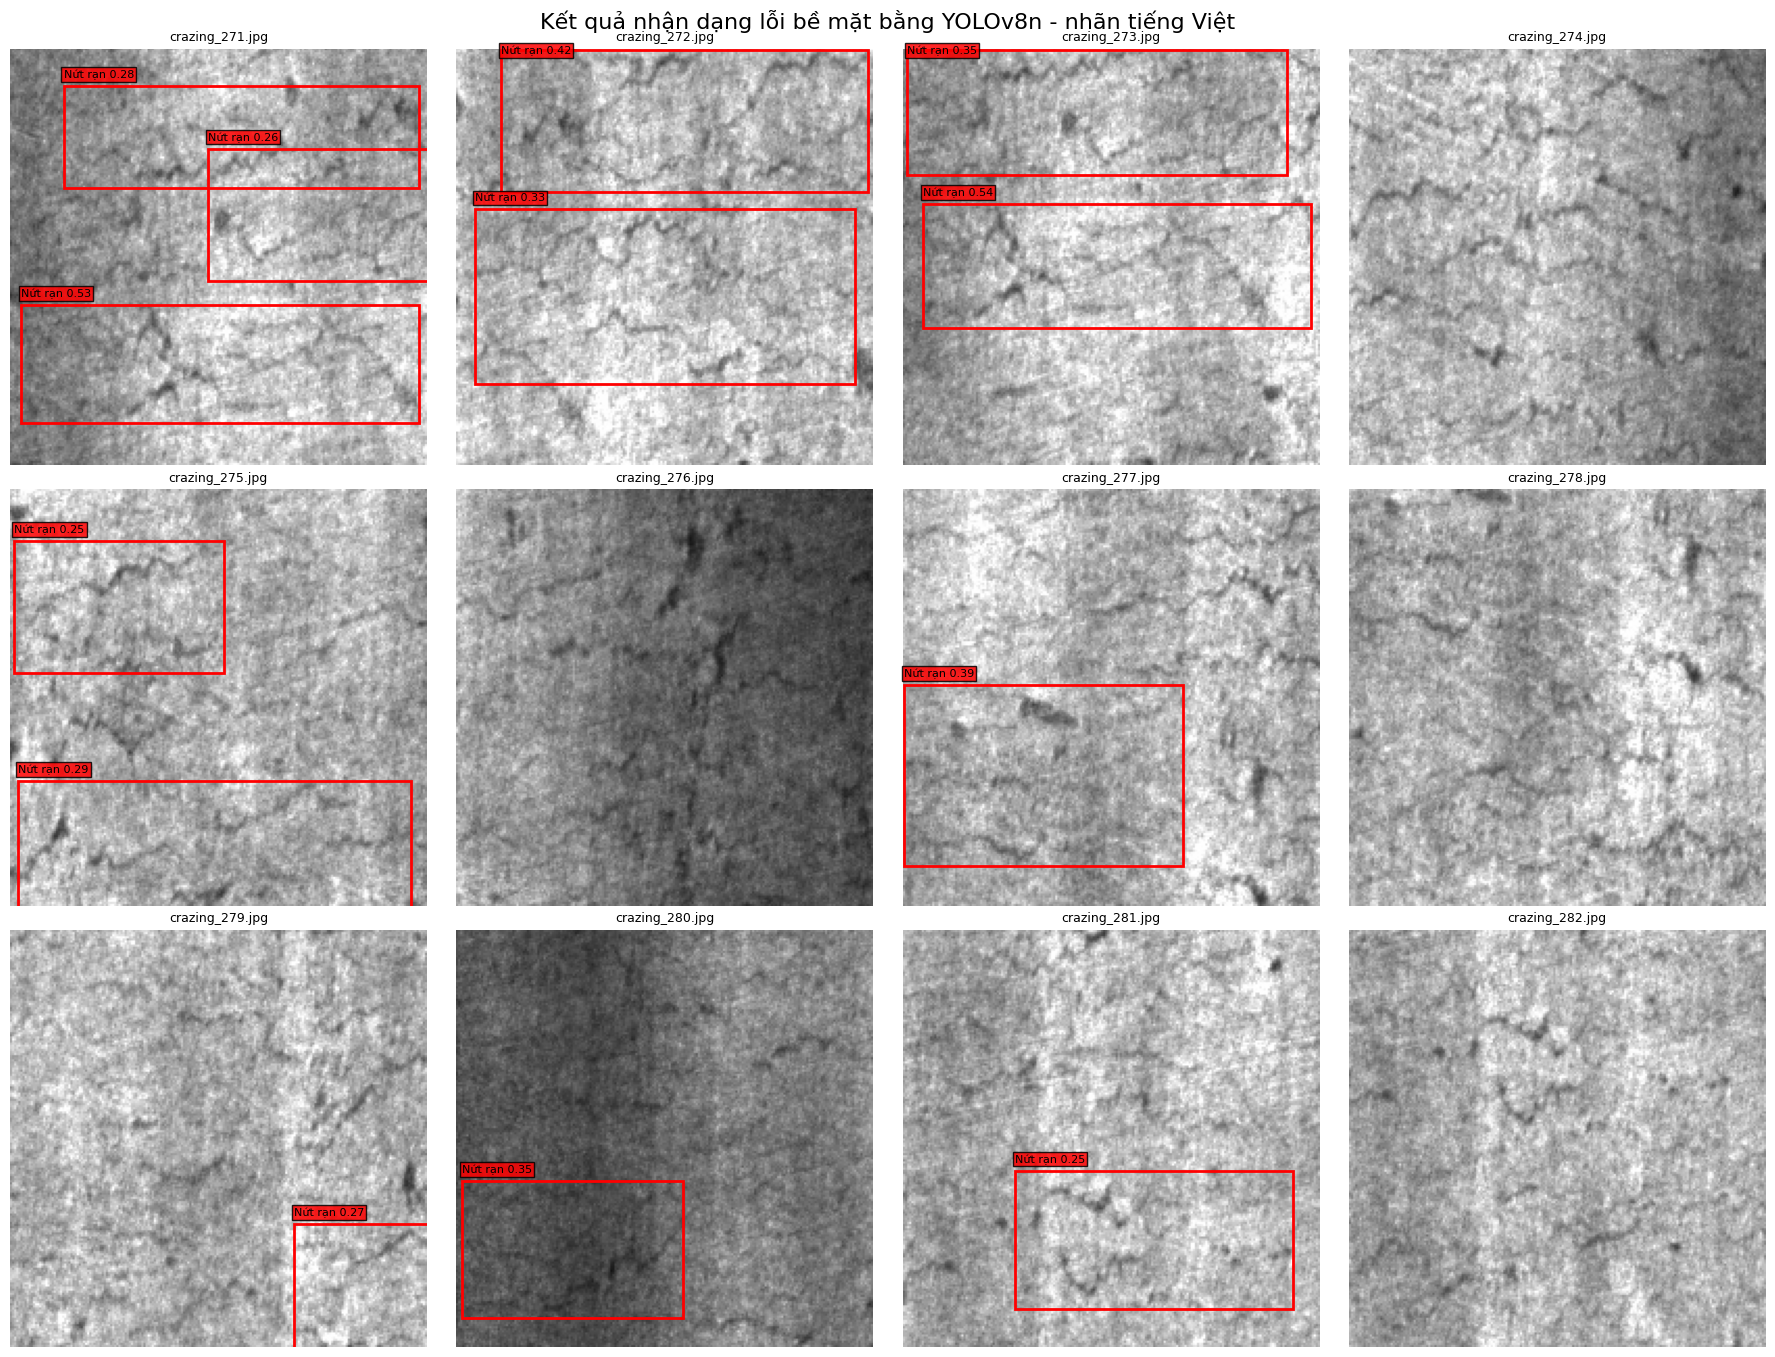

In [5]:
def metric_value(metrics, name):
    box = getattr(metrics, "box", None)
    return float(getattr(box, name, np.nan)) if box is not None else np.nan


def draw_prediction_grid(results, image_paths, output_path: Path):
    columns = 4
    rows = int(np.ceil(len(results) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 4.6 * rows))
    axes = np.array(axes).reshape(-1)

    color_map = {
        0: "red",
        1: "deepskyblue",
        2: "darkorange",
        3: "gold",
        4: "yellowgreen",
        5: "magenta",
    }

    for ax, result, image_path in zip(axes, results, image_paths):
        image_rgb = cv2.cvtColor(result.orig_img, cv2.COLOR_BGR2RGB)
        ax.imshow(image_rgb)
        ax.set_title(image_path.name, fontsize=9)

        if result.boxes is not None:
            for box in result.boxes:
                class_id = int(box.cls.item())
                confidence = float(box.conf.item())
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                color = color_map.get(class_id, "lime")
                label = f"{CLASSES_VI.get(class_id, 'Không xác định')} {confidence:.2f}"
                ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, edgecolor=color, linewidth=2))
                ax.text(x1, max(2, y1 - 4), label, fontsize=8, color="black",
                        bbox={"facecolor": color, "alpha": 0.85, "pad": 1.5})

        ax.axis("off")

    for ax in axes[len(results):]:
        ax.axis("off")

    fig.suptitle("Kết quả nhận dạng lỗi bề mặt bằng YOLOv8n - nhãn tiếng Việt", fontsize=16)
    plt.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


metrics_rows = []
if BEST_PT.exists() and ULTRALYTICS_OK and SPLIT_YAML and TRAIN_GPU_OK:
    best_model = YOLO(str(BEST_PT))

    validation_metrics = best_model.val(data=str(SPLIT_YAML), split="val", device=0, verbose=False)
    test_metrics = best_model.val(data=str(SPLIT_YAML), split="test", device=0, verbose=False)

    for split_name, metrics in [("validation", validation_metrics), ("test", test_metrics)]:
        metrics_rows.append({
            "tap_du_lieu": split_name,
            "precision": metric_value(metrics, "mp"),
            "recall": metric_value(metrics, "mr"),
            "mAP50": metric_value(metrics, "map50"),
            "mAP50_95": metric_value(metrics, "map"),
        })

    metrics_df = pd.DataFrame(metrics_rows)
    metrics_df.to_csv(OUTPUT_DIR / "metrics_yolov8.csv", index=False)
    display(metrics_df)

    test_paths = [Path(line.strip()) for line in (SPLIT_DIR / "test.txt").read_text(encoding="utf-8").splitlines() if line.strip()]
    chosen_paths = test_paths[:MAX_PREDICTION_IMAGES]
    results = best_model.predict(
        source=[str(path) for path in chosen_paths],
        conf=CONFIDENCE_THRESHOLD,
        device=0,
        save=False,
        verbose=False,
    )
    draw_prediction_grid(results, chosen_paths, PREDICTION_DIR / "du_doan_yolov8_tieng_viet.png")

    prediction_rows = []
    for result, image_path in zip(results, chosen_paths):
        if result.boxes is None:
            continue
        for box in result.boxes:
            class_id = int(box.cls.item())
            prediction_rows.append({
                "anh": image_path.name,
                "loai_loi_tieng_viet": CLASSES_VI.get(class_id, "Không xác định"),
                "do_tin_cay": float(box.conf.item()),
            })
    pd.DataFrame(prediction_rows).to_csv(PREDICTION_DIR / "du_doan_yolov8_tieng_viet.csv", index=False)
else:
    print("Chưa có best.pt từ GPU Kaggle, nên chưa tạo ảnh dự đoán thật.")


## Hoàn thành Tuần 2

Ảnh cần trình bày trong báo cáo là:

`outputs/week02_detection/predictions/du_doan_yolov8_tieng_viet.png`

Ảnh này có lưới nhiều ảnh, khung bao, độ tin cậy và **nhãn tiếng Việt**, theo đúng dạng đầu ra mong muốn. Chỉ dùng ảnh này sau khi `best.pt` và `metrics_yolov8.csv` đã được sinh ra từ GPU Kaggle.


## Tạo lưới ảnh nhận dạng tiếng Việt cho báo cáo

Sau khi `best.pt` đã tạo từ GPU Kaggle, mở terminal tại project root và chạy:

```powershell
python scripts/tao_luoi_du_doan_tieng_viet.py --so-anh 12
```

Kết quả được lưu tại:

`outputs/week02_detection/predictions/du_doan_yolov8_tieng_viet.png`

Ảnh gồm lưới 12 ảnh, khung bao, nhãn tiếng Việt và độ tin cậy giống yêu cầu minh họa của đề tài.
